# 🚗 Pothole Detection: Comparative Deep Learning Benchmark
### Architectures Evaluated:
1. **Custom Baseline CNN**
2. **AlexNet Architecture**
3. **GoogLeNet (Inception Architecture)**
4. **VGG-16**
5. **VGG-19**

## Step 1: Import Libraries & Environment Setup

In [1]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow Version: 2.21.0


GPU Available: False


## Step 2: Dataset Loading, Exploration & Data Augmentation

In [2]:
dataset_dir = 'pothole-detection-dataset'
IMG_SIZE = (128, 128)
INPUT_SHAPE = (128, 128, 3)
BATCH_SIZE = 32

# Data Augmentation for Training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

# Rescaling for Validation
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    dataset_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    dataset_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False
)

class_indices = train_generator.class_indices
idx_to_class = {v: k for k, v in class_indices.items()}
val_labels = val_generator.classes
print(f"Class Mapping: {class_indices}")

Found 546 images belonging to 2 classes.


Found 135 images belonging to 2 classes.


Class Mapping: {'normal': 0, 'potholes': 1}


### Visualizing Sample Images from Dataset

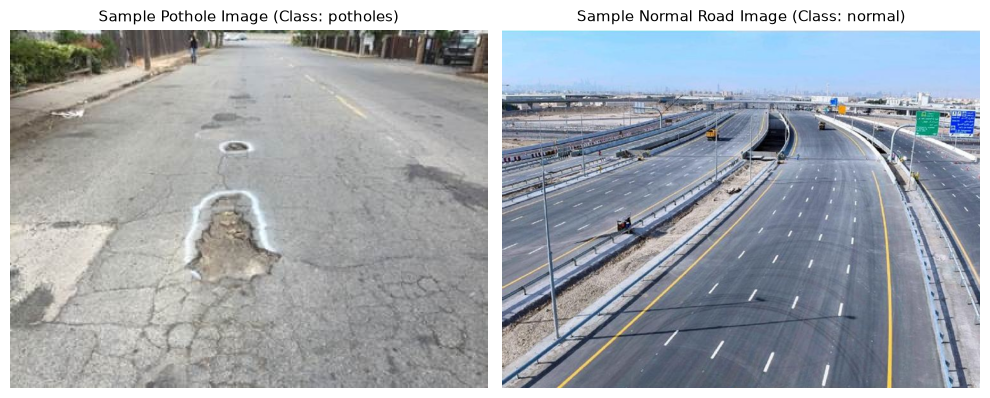

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sample_pothole = cv2.imread('pothole-detection-dataset/potholes/125.jpg')
if sample_pothole is not None:
    axes[0].imshow(cv2.cvtColor(sample_pothole, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Sample Pothole Image (Class: potholes)", fontsize=11)
    axes[0].axis('off')

sample_normal = cv2.imread('pothole-detection-dataset/normal/11.jpg')
if sample_normal is not None:
    axes[1].imshow(cv2.cvtColor(sample_normal, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Sample Normal Road Image (Class: normal)", fontsize=11)
    axes[1].axis('off')

plt.tight_layout()
plt.show()

## Step 3: Model Architecture Definitions
Here we define all 5 architectures:
1. **Custom CNN**: Multi-stage Conv2D + MaxPooling2D + Dense + Dropout.
2. **AlexNet**: Multi-scale convolutional filter bank (11x11, 5x5, 3x3) + Batch Normalization + Overlapping MaxPool + Dense Dropout.
3. **GoogLeNet**: Deep Inception modules with parallel multi-resolution convolutions (1x1, 3x3, 5x5) and 1x1 dimensionality reduction.
4. **VGG-16**: 16-layer deep network utilizing small 3x3 convolutional kernels.
5. **VGG-19**: 19-layer deep network with additional convolutional depth.

In [4]:
# Model 1: Custom CNN
def build_custom_cnn(input_shape=INPUT_SHAPE):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ], name="Custom_CNN")
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Model 2: AlexNet
def build_alexnet(input_shape=INPUT_SHAPE):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(64, (7, 7), strides=2, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((3, 3), strides=2, padding='same'),
        layers.Conv2D(192, (5, 5), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((3, 3), strides=2, padding='same'),
        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((3, 3), strides=2, padding='same'),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ], name="AlexNet")
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Model 3: GoogLeNet (Inception)
def _inception_block(x, f1, f3_r, f3, f5_r, f5, pool_proj):
    b1 = layers.Conv2D(f1, (1, 1), padding='same', activation='relu')(x)
    b2 = layers.Conv2D(f3_r, (1, 1), padding='same', activation='relu')(x)
    b2 = layers.Conv2D(f3, (3, 3), padding='same', activation='relu')(b2)
    b3 = layers.Conv2D(f5_r, (1, 1), padding='same', activation='relu')(x)
    b3 = layers.Conv2D(f5, (5, 5), padding='same', activation='relu')(b3)
    b4 = layers.MaxPooling2D((3, 3), strides=1, padding='same')(x)
    b4 = layers.Conv2D(pool_proj, (1, 1), padding='same', activation='relu')(b4)
    return layers.concatenate([b1, b2, b3, b4], axis=-1)

def build_googlenet(input_shape=INPUT_SHAPE):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv2D(64, (7, 7), strides=2, padding='same', activation='relu')(inputs)
    x = layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, (1, 1), padding='same', activation='relu')(x)
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)
    x = _inception_block(x, 64, 96, 128, 16, 32, 32)
    x = _inception_block(x, 128, 128, 192, 32, 64, 64)
    x = layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)
    x = _inception_block(x, 192, 96, 208, 16, 48, 64)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = Model(inputs=inputs, outputs=outputs, name="GoogLeNet_Inception")
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Model 4: VGG-16
def build_vgg16(input_shape=INPUT_SHAPE):
    base = tf.keras.applications.VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    for layer in base.layers[:-4]:
        layer.trainable = False
    inputs = layers.Input(shape=input_shape)
    x = base(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = Model(inputs=inputs, outputs=outputs, name="VGG16")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Model 5: VGG-19
def build_vgg19(input_shape=INPUT_SHAPE):
    base = tf.keras.applications.VGG19(weights='imagenet', include_top=False, input_shape=input_shape)
    for layer in base.layers[:-4]:
        layer.trainable = False
    inputs = layers.Input(shape=input_shape)
    x = base(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = Model(inputs=inputs, outputs=outputs, name="VGG19")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return model

print("All 5 model architecture builders defined successfully.")

All 5 model architecture builders defined successfully.


## Step 4: Training & Evaluating All 5 Models

In [5]:
models_dict = {
    'Custom CNN': build_custom_cnn(),
    'AlexNet': build_alexnet(),
    'GoogLeNet': build_googlenet(),
    'VGG16': build_vgg16(),
    'VGG19': build_vgg19()
}

EPOCHS = 10
histories = {}
benchmark_metrics = []
predictions_dict = {}

for name, model in models_dict.items():
    print(f"\n>>> Training {name} for {EPOCHS} epochs...")
    start_t = time.time()
    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        verbose=1
    )
    duration = time.time() - start_t
    histories[name] = history.history
    
    # Evaluate on Validation Set
    val_generator.reset()
    val_probs = model.predict(val_generator, verbose=0).flatten()
    val_preds = (val_probs >= 0.5).astype(int)
    predictions_dict[name] = (val_preds, val_probs)
    
    acc = accuracy_score(val_labels, val_preds)
    prec = precision_score(val_labels, val_preds, zero_division=0)
    rec = recall_score(val_labels, val_preds, zero_division=0)
    f1 = f1_score(val_labels, val_preds, zero_division=0)
    auc = roc_auc_score(val_labels, val_probs)
    
    benchmark_metrics.append({
        'Model': name,
        'Validation Accuracy (%)': round(acc * 100, 2),
        'Validation Loss': round(history.history['val_loss'][-1], 4),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score (%)': round(f1 * 100, 2),
        'ROC-AUC': round(auc, 4),
        'Training Time (s)': round(duration, 1)
    })

df_comparison = pd.DataFrame(benchmark_metrics)
display(df_comparison)

       0/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/58889256 ━━━━━━━━━━━━━━━━━━━━ 9:26 10us/step

   32768/58889256 ━━━━━━━━━━━━━━━━━━━━ 7:16 7us/step 

   49152/58889256 ━━━━━━━━━━━━━━━━━━━━ 8:08 8us/step

   73728/58889256 ━━━━━━━━━━━━━━━━━━━━ 6:16 6us/step

...

16/18 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.9938 - loss: 0.0161

17/18 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.9942 - loss: 0.0159

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9945 - loss: 0.0154

18/18 ━━━━━━━━━━━━━━━━━━━━ 49s 3s/step - accuracy: 0.9945 - loss: 0.0154 - val_accuracy: 0.9481 - val_loss: 0.1690


,Model,Validation Accuracy (%),Validation Loss,Precision (%),Recall (%),F1-Score (%),ROC-AUC,Training Time (s)
0,Custom CNN,84.44,0.4398,86.67,80.00,83.20,0.9200,329.2
1,AlexNet,62.22,0.6301,65.91,44.62,53.21,0.7257,427.6
2,GoogLeNet,67.41,0.6246,70.59,55.38,62.07,0.7310,701.4
3,VGG16,97.78,0.0661,96.97,98.46,97.71,0.9985,441.5
4,VGG19,94.81,0.1690,100.00,89.23,94.31,0.9996,418.5


## Step 5: Comparative Performance Visualizations
- Accuracy & F1-score comparison
- Training & Validation loss/accuracy curves across epochs

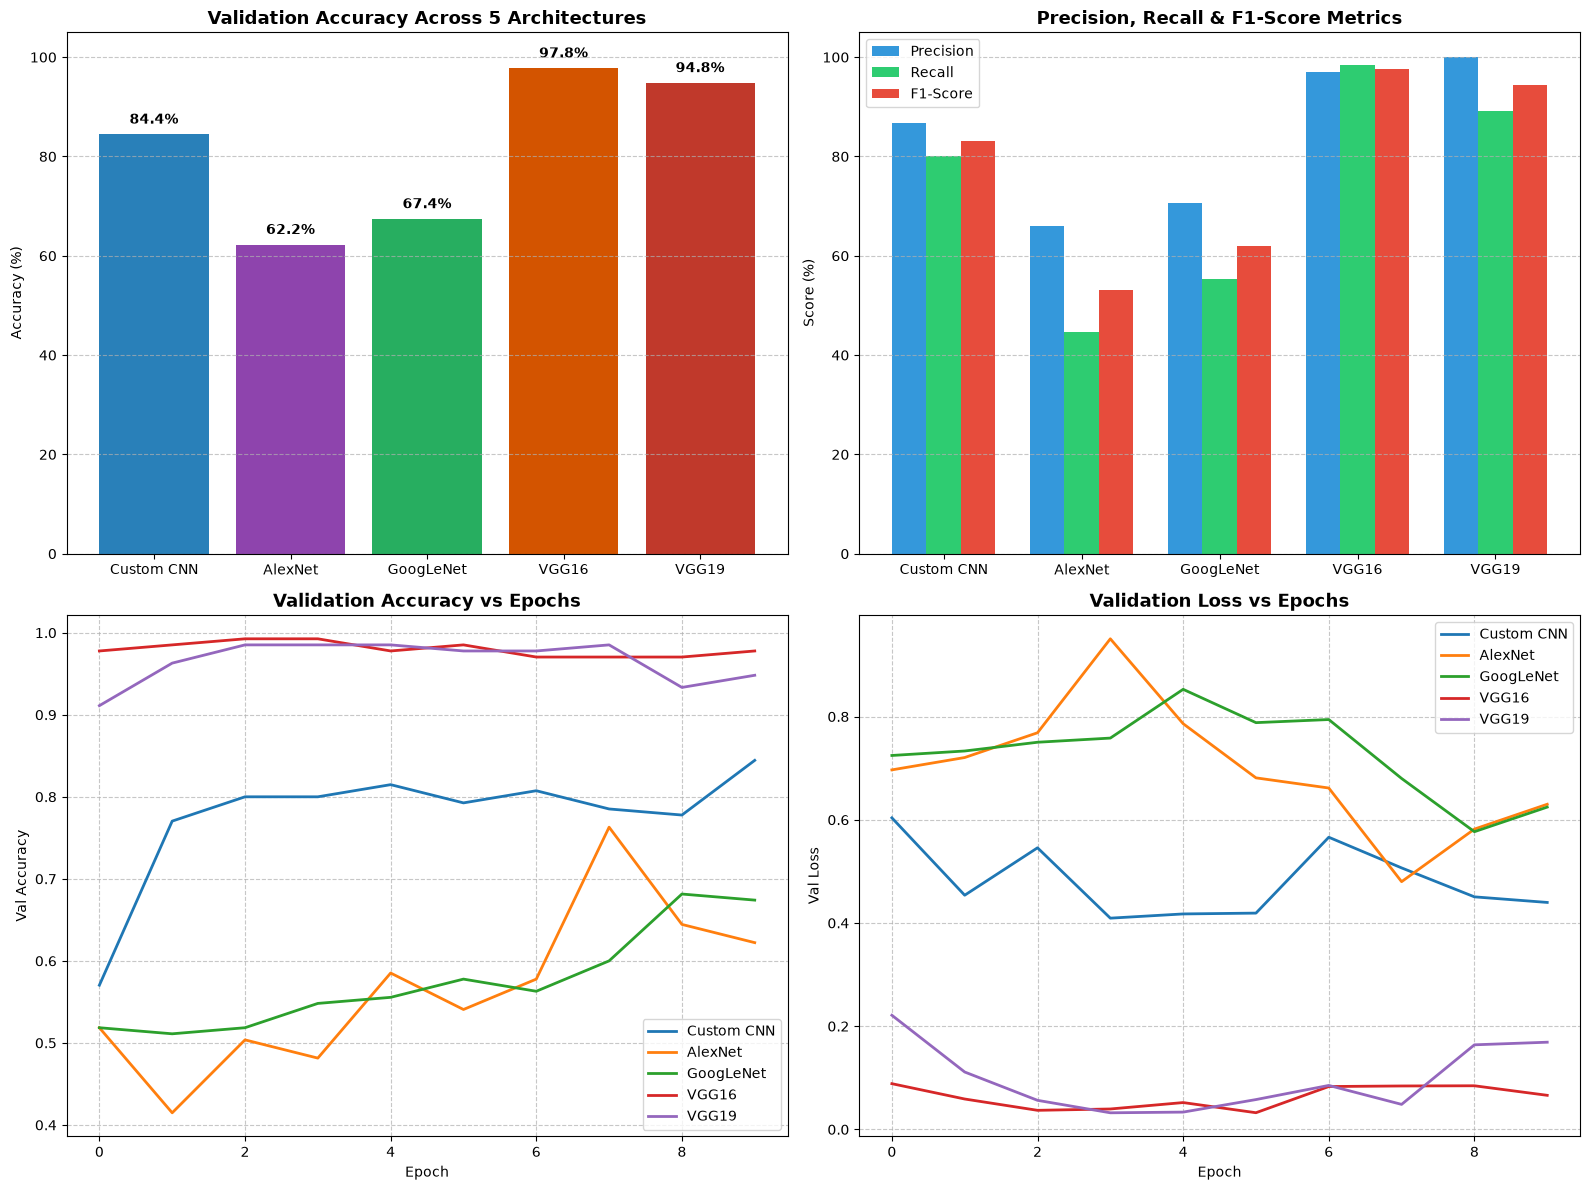

In [6]:
plt.figure(figsize=(16, 12))

# 1. Validation Accuracy Comparison
plt.subplot(2, 2, 1)
palette = ['#2980b9', '#8e44ad', '#27ae60', '#d35400', '#c0392b']
bars = plt.bar(df_comparison['Model'], df_comparison['Validation Accuracy (%)'], color=palette)
plt.title('Validation Accuracy Across 5 Architectures', fontsize=13, fontweight='bold')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 2. F1-Score & Precision Comparison
plt.subplot(2, 2, 2)
x = np.arange(len(df_comparison['Model']))
w = 0.25
plt.bar(x - w, df_comparison['Precision (%)'], w, label='Precision', color='#3498db')
plt.bar(x, df_comparison['Recall (%)'], w, label='Recall', color='#2ecc71')
plt.bar(x + w, df_comparison['F1-Score (%)'], w, label='F1-Score', color='#e74c3c')
plt.title('Precision, Recall & F1-Score Metrics', fontsize=13, fontweight='bold')
plt.xticks(x, df_comparison['Model'])
plt.ylabel('Score (%)')
plt.ylim(0, 105)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 3. Validation Accuracy Progression
plt.subplot(2, 2, 3)
for name, hist in histories.items():
    plt.plot(hist['val_accuracy'], label=f"{name}", linewidth=2)
plt.title('Validation Accuracy vs Epochs', fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Val Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# 4. Validation Loss Progression
plt.subplot(2, 2, 4)
for name, hist in histories.items():
    plt.plot(hist['val_loss'], label=f"{name}", linewidth=2)
plt.title('Validation Loss vs Epochs', fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Val Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Step 6: Confusion Matrices for All 5 Architectures

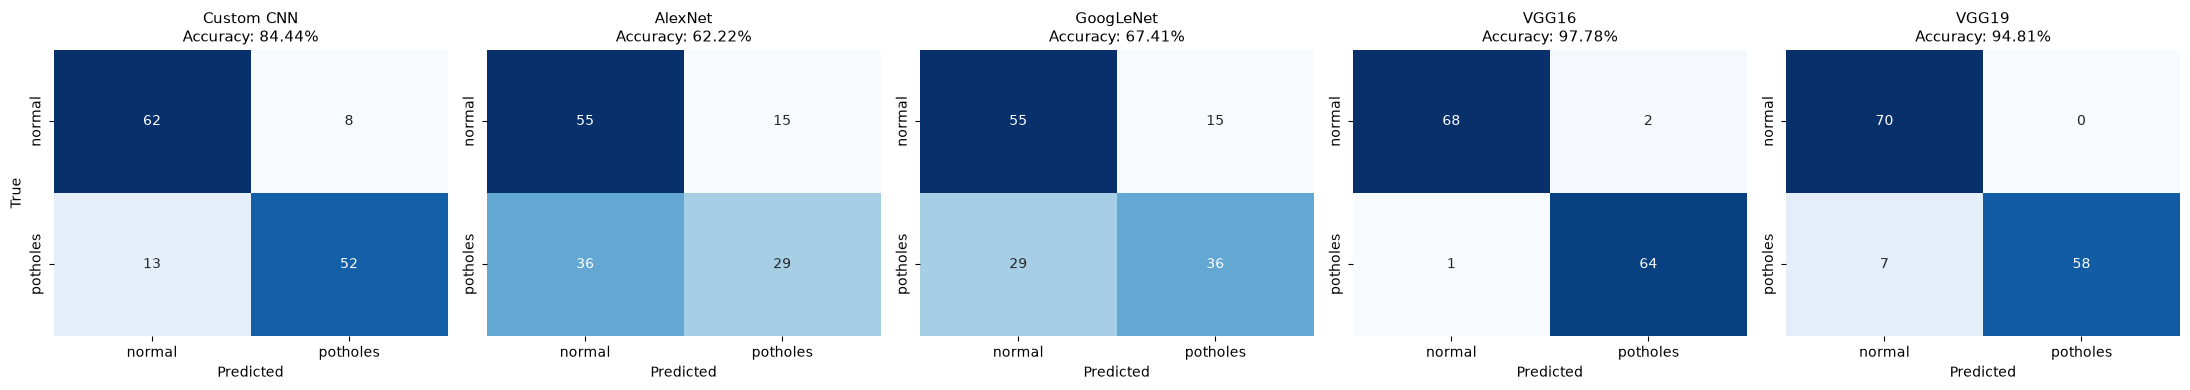

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
class_names = [idx_to_class[0], idx_to_class[1]]

for i, (name, (preds, _)) in enumerate(predictions_dict.items()):
    cm = confusion_matrix(val_labels, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    axes[i].set_title(f"{name}\nAccuracy: {df_comparison.loc[df_comparison['Model']==name, 'Validation Accuracy (%)'].values[0]}%", fontsize=11)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('True' if i == 0 else '')

plt.tight_layout()
plt.show()

## Step 7: Multi-Model Inference on Test Pothole Images

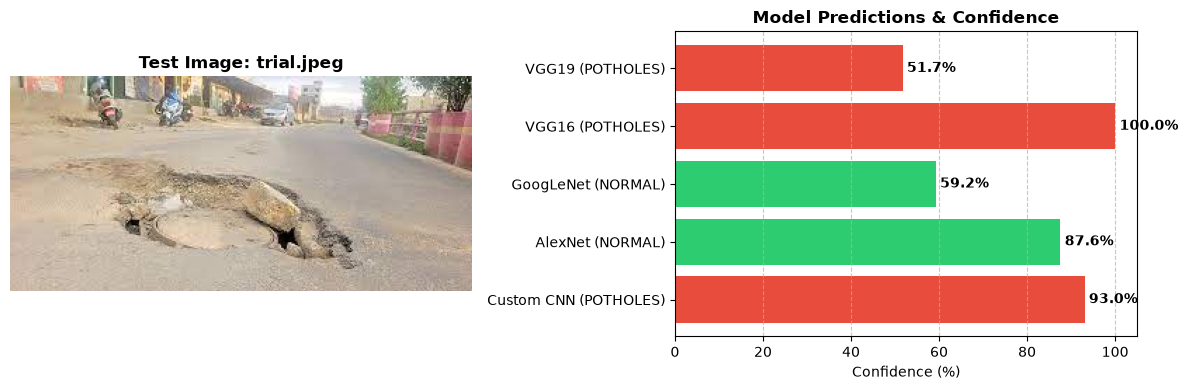

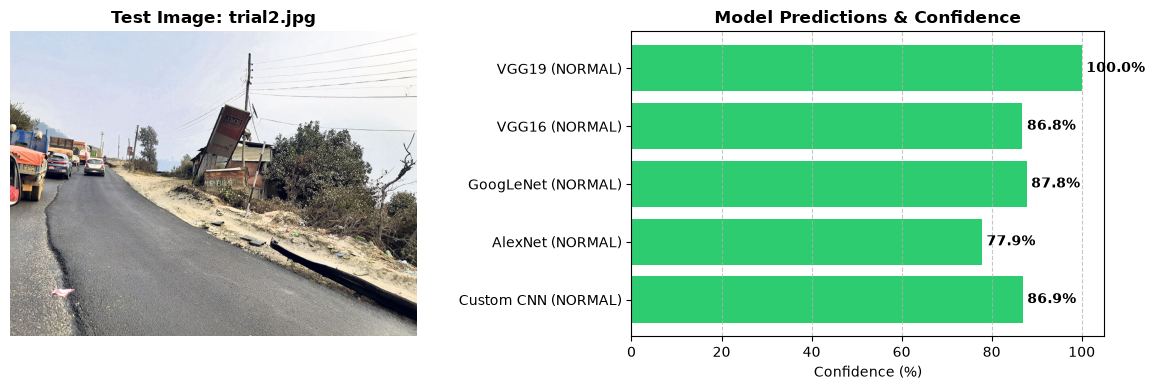

In [8]:
test_files = ['pothole-detection-dataset/trial.jpeg', 'pothole-detection-dataset/trial2.jpg']

for file_path in test_files:
    if os.path.exists(file_path):
        orig_img = cv2.imread(file_path)
        img = load_img(file_path, target_size=IMG_SIZE)
        arr = img_to_array(img) / 255.0
        arr = np.expand_dims(arr, axis=0)
        
        plt.figure(figsize=(12, 4))
        
        # Show Test Image
        plt.subplot(1, 2, 1)
        plt.imshow(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB))
        plt.title(f"Test Image: {os.path.basename(file_path)}", fontsize=12, fontweight='bold')
        plt.axis('off')
        
        # Bar plot of predictions
        model_names = []
        confidences = []
        labels = []
        
        for m_name, model in models_dict.items():
            prob = model.predict(arr, verbose=0)[0][0]
            pred_idx = 1 if prob >= 0.5 else 0
            conf = prob if pred_idx == 1 else (1.0 - prob)
            label = idx_to_class[pred_idx]
            
            model_names.append(m_name)
            confidences.append(conf * 100)
            labels.append(label.upper())
            
        plt.subplot(1, 2, 2)
        y_pos = np.arange(len(model_names))
        barlist = plt.barh(y_pos, confidences, color=['#e74c3c' if l == 'POTHOLES' else '#2ecc71' for l in labels])
        plt.yticks(y_pos, [f"{m} ({l})" for m, l in zip(model_names, labels)])
        plt.xlabel('Confidence (%)')
        plt.xlim(0, 105)
        plt.title('Model Predictions & Confidence', fontsize=12, fontweight='bold')
        for j, v in enumerate(confidences):
            plt.text(v + 1, j, f"{v:.1f}%", va='center', fontweight='bold')
        plt.grid(axis='x', linestyle='--', alpha=0.7)
        
        plt.tight_layout()
        plt.show()